# COCOVQA TEXT Evaluation with Exact Match Accuracy


In [2]:
from pathlib import Path
import sys
import json
import os
import matplotlib.pyplot as plt

COCOVQA_TEXT_DIR = Path.cwd()
sys.path.append(str(COCOVQA_TEXT_DIR))

In [3]:
results_path = results_file = next((f for f in os.listdir(COCOVQA_TEXT_DIR) if 'results' in f), None)
if results_path:
    with open(COCOVQA_TEXT_DIR / results_path, 'r') as f:
        results = [json.loads(line) for line in f]
else:
    results = None

In [4]:
models_collection = set()
for score in results:
    exp_name = score['experiment_name'].split('/')[0]
    if 'finetuned' not in exp_name:
        models_collection.add(exp_name)

data = { exp: {} for exp in models_collection }
checkpoint_steps = [str(i) for i in range(1000, 10001, 1000)]
for collection in models_collection:
    for experiment in results:
        exp_name = experiment['experiment_name'].split('/')[0]
        # Exact match on the collection name (before the '/')
        if exp_name == collection:
            step = experiment['experiment_name'].split('-')[-1]
            if step in checkpoint_steps:
                data[collection][int(step)] = experiment['accuracy']

# Find experiment ending with 'finetuned'
finetuned_exp = next((exp for exp in results if exp['experiment_name'].endswith('finetuned')), None)

# Find experiment ending with 'pretrained'
pretrained_exp = next((exp for exp in results if exp['experiment_name'].endswith('pretrained')), None)
if finetuned_exp:
    data['finetuned'] = finetuned_exp['accuracy']
if pretrained_exp:
    data['pretrained'] = pretrained_exp['accuracy']
data

{'Llava1.5-7B': {1000: 0.7956,
  2000: 0.7812,
  3000: 0.7564,
  4000: 0.7752,
  5000: 0.7952,
  6000: 0.7212,
  7000: 0.7956,
  8000: 0.7796,
  9000: 0.7792,
  10000: 0.79},
 'Llava1.5-7B-18-32': {1000: 0.5112,
  2000: 0.5848,
  3000: 0.5756,
  4000: 0.616,
  5000: 0.6116,
  6000: 0.6188,
  7000: 0.6112,
  8000: 0.6152,
  9000: 0.6076,
  10000: 0.6144},
 'Llava1.5-7B-2-18': {1000: 0.7192,
  2000: 0.7256,
  3000: 0.7008,
  4000: 0.7388,
  5000: 0.7296,
  6000: 0.63,
  7000: 0.7464,
  8000: 0.7308,
  9000: 0.7364,
  10000: 0.742},
 'Llava1.5-7B-frozen': {1000: 0.4984,
  2000: 0.4584,
  3000: 0.4948,
  4000: 0.4728,
  5000: 0.4408,
  6000: 0.4428,
  7000: 0.4388,
  8000: 0.4392,
  9000: 0.4416,
  10000: 0.4404},
 'Llava1.5-7B-2-2': {1000: 0.48,
  2000: 0.4504,
  3000: 0.4488,
  4000: 0.4376,
  5000: 0.4148,
  6000: 0.4168,
  7000: 0.4128,
  8000: 0.414,
  9000: 0.4184,
  10000: 0.4168},
 'finetuned': 0.756,
 'pretrained': 0.5928}

In [5]:
models_collection

{'Llava1.5-7B',
 'Llava1.5-7B-18-32',
 'Llava1.5-7B-2-18',
 'Llava1.5-7B-2-2',
 'Llava1.5-7B-frozen'}

In [6]:
basename = "Llava1.5-7B"
NAMES_MAPPING = {
    basename: "full",
    f"{basename}-2-18": "2-18",
    f"{basename}-18-32": "18-32",
    f"{basename}-2-2": "2-2",
    f"{basename}-frozen": "frozen_llm",
    "finetuned": "FM",
    "pretrained": "PM"
}

COLOR_SCHEME = {
    'full': '#08519c',      # Dark blue - all layers fine-tuned
    '2-18': '#6baed6',      # Medium blue - early-upper layers
    '18-32': '#9ecae1',     # Light blue - upper layers only
    '2-2': '#c6dbef',     # Very light blue - middle layers (reserved)
    'frozen_llm': '#006d2c',   # Dark green - frozen projector, all LLM layers trained
    'PM': 'black',
    'FM': 'red',
}

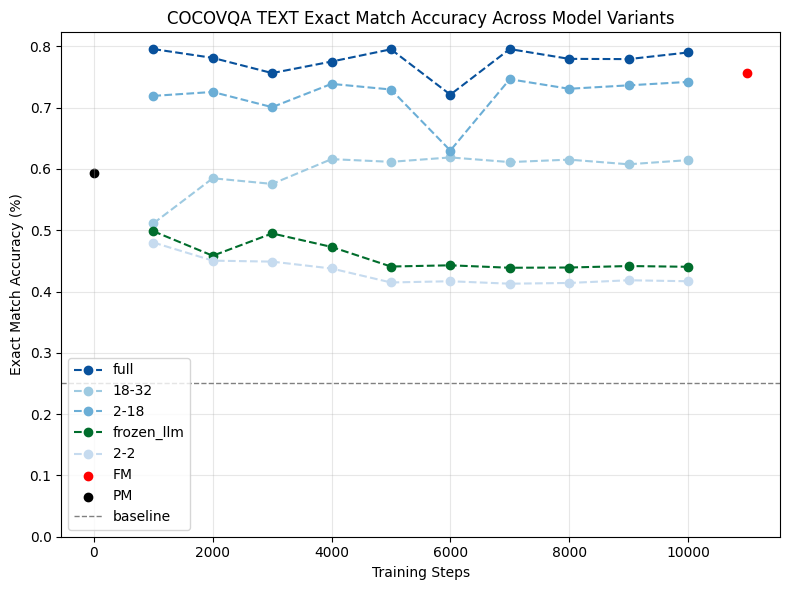

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
for collection in models_collection:
    label = NAMES_MAPPING.get(collection, collection)
    color = COLOR_SCHEME.get(label, "#000000")
    if data[collection]:  # Only plot if there's data
        steps, scores = zip(*sorted(data[collection].items()))
        ax.plot(
            steps,
            scores,
            label=label,
            color=color,
            marker="o",
            linestyle="--",
        )

if "finetuned" in data:
    label = NAMES_MAPPING.get("finetuned", "finetuned")
    color = COLOR_SCHEME.get(label, "red")
    ax.scatter(11000, data["finetuned"], label=label, color=color, marker="o")

if "pretrained" in data:
    label = NAMES_MAPPING.get("pretrained", "pretrained")
    color = COLOR_SCHEME.get(label, "green")
    ax.scatter(0, data["pretrained"], label=label, color=color, marker="o")
    
ax.axhline(y=0.25, color='gray', linestyle='--', linewidth=1, label='baseline')

ax.set_ylim(ymin=0)

ax.set_xlabel("Training Steps")
ax.set_ylabel("Exact Match Accuracy (%)")
ax.set_title("COCOVQA TEXT Exact Match Accuracy Across Model Variants")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
steps, scores = zip(*data[f"{basename}-2-2"].items())
steps, scores


((1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000),
 (0.48, 0.4504, 0.4488, 0.4376, 0.4148, 0.4168, 0.4128, 0.414, 0.4184, 0.4168))

In [9]:
import os